<a href="https://colab.research.google.com/github/veekshavkamath-blip/CRIME-LOGISTIC-REGRESSION/blob/main/TITANIC_LOGISTIC_REGRESSION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [150]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [151]:
data=pd.read_csv('titanic.csv')

In [152]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [153]:
print(data.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [154]:
print(data.shape)

(891, 12)


In [155]:
data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [156]:
data = data.drop(columns=["Cabin","PassengerId","Ticket","Name"])
data = pd.get_dummies(data, dtype=float)

In [157]:
data["Age"]=data["Age"].fillna(data["Age"].median())

In [158]:
print(data.isnull().sum())
print(data.shape)
print(len(data))

Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_female    0
Sex_male      0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
dtype: int64
(891, 11)
891


In [159]:
y=data["Survived"].values
x=data.drop(columns="Survived").values.astype(float)


In [160]:
split=int(0.8*len(x))
idx=np.arange(len(x))
rng=np.random.default_rng(42)
rng.shuffle(idx)
train_idx,test_idx=idx[:split],idx[split:]
x_train,x_test=x[train_idx],x[test_idx]
y_train,y_test=y[train_idx],y[test_idx]

In [161]:
X = x_train.mean(axis=0)
sigma= x_train.std(axis=0)
sigma[sigma == 0] = 1
x_train = (x_train - X) / sigma
x_test = (x_test - X) / sigma


In [162]:
x_train = np.c_[np.ones(len(x_train)), x_train]
x_test = np.c_[np.ones(len(x_test)), x_test]
print(x_train.shape, x_test.shape)


(712, 11) (179, 11)


In [163]:
def sigmoid(z):
  return 1/(1+np.exp(-z))

def gradient_descent(x,y,a=0.01,lam=0,iter=300):
  m,n=x.shape
  w = np.zeros(n)
  costs=[]
  for _ in range(iter):
    p=sigmoid(x@w)
    reg = lam * w
    err=p-y
    reg[0] = 0
    w -= a * (x.T @ err + reg) / m
    cost = -np.mean(y * np.log(p ) + (1 - y) * np.log(1 - p))
    cost += lam * np.sum(w[1:] ** 2) / (2 * m)
    costs.append(cost)
  return(w,costs)



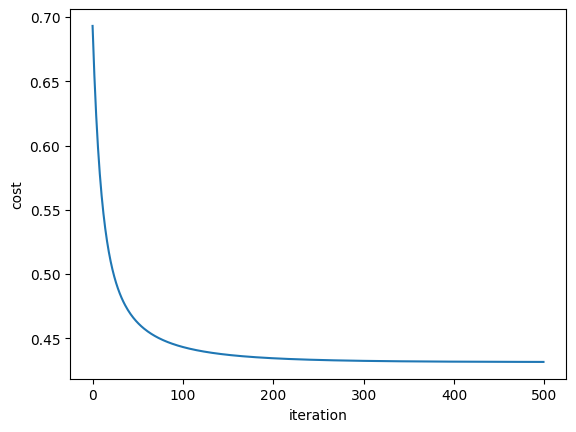

In [165]:
plt.plot(costs)
plt.xlabel("iteration"); plt.ylabel("cost")
plt.show()

In [171]:
w,costs = gradient_descent(x_train, y_train, a=0.1, lam=1, iter=500)

def predict(X, w, threshold=0.5):
    return (sigmoid(X @ w) >= threshold).astype(int)

pred = predict(x_test, w)
tp = np.sum((pred == 1) & (y_test == 1))
fp = np.sum((pred == 1) & (y_test == 0))
fn = np.sum((pred == 0) & (y_test == 1))

print("Accuracy :", np.mean(pred == y_test))
print("Precision:", tp / (tp + fp))
print("Recall   :", tp / (tp + fn))

Accuracy : 0.7374301675977654
Precision: 0.6410256410256411
Recall   : 0.7246376811594203
